<a href="https://colab.research.google.com/github/julietmuthoni325-creator/course-project/blob/main/Week_6_Machine_Equipment_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

import pandas as pd

url = "https://archive.ics.uci.edu/static/public/601/data.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Dataset shape: (10000, 14)
Column names:
['UID', 'Product ID', 'Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Match feature names to the actual dataset columns
possible_features = {
    "Air temperature": ["Air temperature", "Air temperature [K]"],
    "Process temperature": ["Process temperature", "Process temperature [K]"],
    "Rotational speed": ["Rotational speed", "Rotational speed [rpm]"],
    "Torque": ["Torque", "Torque [Nm]"],
    "Tool wear": ["Tool wear", "Tool wear [min]"]
}

features = []

for options in possible_features.values():
    match = next((name for name in options if name in df.columns), None)
    if match is None:
        raise ValueError(f"Feature not found. Available columns: {df.columns.tolist()}")
    features.append(match)

X = df[features].copy()

print("Selected features:", X.columns.tolist())
display(X.head())


Selected features: ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,298.1,308.6,1551,42.8,0
1,298.2,308.7,1408,46.3,3
2,298.1,308.5,1498,49.4,5
3,298.2,308.6,1433,39.5,7
4,298.2,308.7,1408,40.0,9


In [6]:

X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features prepared and scaled successfully.")


Features prepared and scaled successfully.


In [7]:

inertias = []
silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

print("Clustering experiments completed.")


Clustering experiments completed.


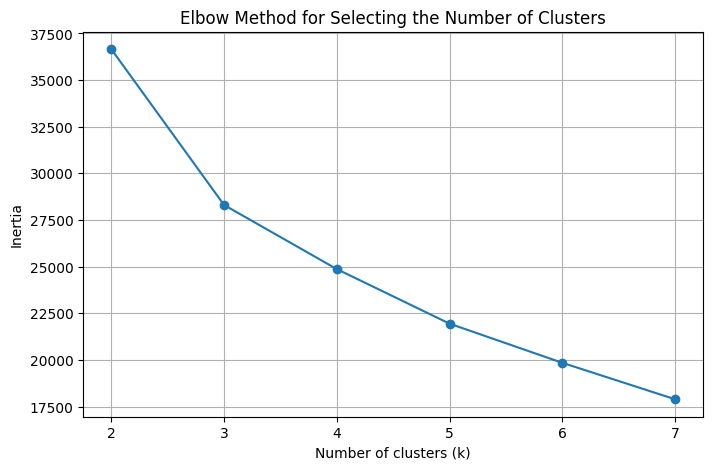

In [8]:

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting the Number of Clusters")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


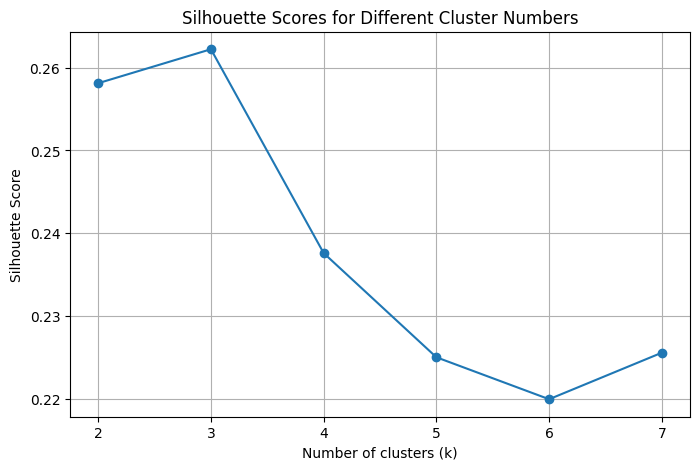

k=2: silhouette score = 0.258
k=3: silhouette score = 0.262
k=4: silhouette score = 0.238
k=5: silhouette score = 0.225
k=6: silhouette score = 0.220
k=7: silhouette score = 0.226


In [9]:

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for Different Cluster Numbers")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

for k, score in zip(k_values, silhouette_scores):
    print(f"k={k}: silhouette score = {score:.3f}")


In [10]:

best_k = 3

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Number of clusters:", best_k)
print(df["Cluster"].value_counts().sort_index())


Number of clusters: 3
Cluster
0    3930
1    4017
2    2053
Name: count, dtype: int64


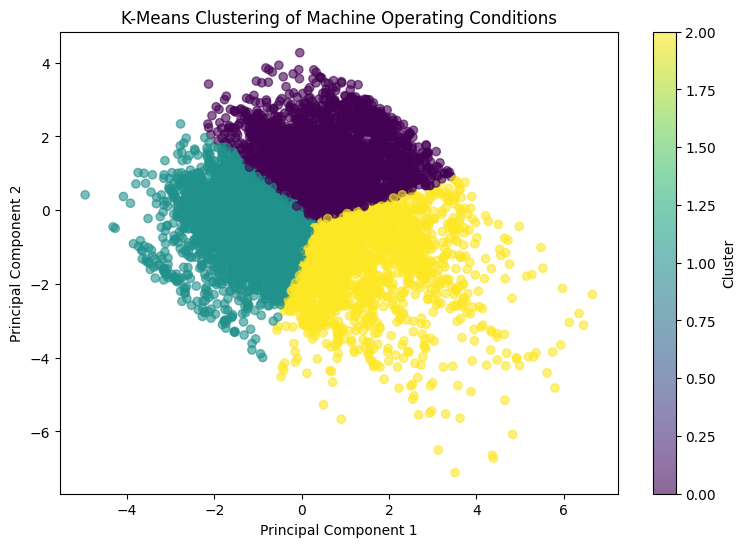

Variance explained by two components: 75.03 %


In [11]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.6
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Machine Operating Conditions")
plt.colorbar(label="Cluster")
plt.show()

print("Variance explained by two components:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


In [12]:

cluster_summary = df.groupby("Cluster")[features].mean().round(2)

print("Average operating conditions for each cluster:")
display(cluster_summary)

print("\nNumber of records in each cluster:")
display(df["Cluster"].value_counts().sort_index())


Average operating conditions for each cluster:


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
Cluster,,,,,
0,301.72,311.25,1469.81,43.64,110.36
1,298.26,308.74,1474.14,43.26,104.62
2,300.12,310.10,1797.26,26.57,109.85



Number of records in each cluster:


,count
Cluster,
0,3930
1,4017
2,2053



## Discussion and Conclusion

In this assignment, I used the K-Means clustering algorithm to group machines according to their operating conditions. I selected air temperature, process temperature, rotational speed, torque and tool wear as the features.

I scaled the features before clustering because they have different units and ranges. I compared different numbers of clusters using the elbow method and silhouette scores, then visualized the groups using PCA.

The model identified three groups of machines. Cluster [insert number] had relatively [high/low] values for [insert features]. Cluster [insert number] showed [describe its characteristics], while Cluster [insert number] had [describe its characteristics].

These groups may represent different operating conditions or equipment usage patterns. They could help biomedical engineers investigate machines that operate under similar conditions and plan further maintenance analysis.

However, the clusters do not automatically indicate whether a machine has failed. Further investigation using real medical equipment maintenance records would be needed to establish their relevance to healthcare equipment.

This assignment helped me understand how unsupervised machine learning can identify patterns in equipment data without using predefined failure labels.
